In [1]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # set to your number of CPU cores

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/loans_clean.csv", low_memory=False)

d = df[(df["term"] == "36 months") & (df["issue_year"].between(2010, 2015))].copy()

# Two engineered features
d["credit_hist_years"] = d["issue_year"] - pd.to_datetime(d["earliest_cr_line"], format="%b-%Y").dt.year
d["loan_to_income"] = d["loan_amnt"] / d["annual_inc"]

train = d[d["issue_year"] <= 2013].copy()
test = d[d["issue_year"] >= 2014].copy()

print("Train:", len(train), "| default rate:", round(train["is_default"].mean() * 100, 2), "%")
print("Test: ", len(test),  "| default rate:", round(test["is_default"].mean() * 100, 2), "%")

Train: 166459 | default rate: 12.39 %
Test:  445589 | default rate: 14.46 %


In [3]:
num = ["loan_amnt", "int_rate", "installment", "annual_inc", "dti", "delinq_2yrs", "fico_avg",
       "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc",
       "credit_hist_years", "loan_to_income"]
cat = ["grade", "emp_length", "home_ownership", "verification_status", "purpose"]

# NEVER use these as features: total_pymnt, realized_profit, loan_status, is_default.
# They are only known after the loan ends (leakage).
print("Features:", len(num) + len(cat))

Features: 19


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
])

logit = Pipeline([("pre", pre), ("m", LogisticRegression(max_iter=1000))])
gbm = Pipeline([("pre", pre), ("m", HistGradientBoostingClassifier(
    max_depth=5, learning_rate=0.08, max_iter=300, random_state=42))])

X_train, y_train = train[num + cat], train["is_default"]
X_test, y_test = test[num + cat], test["is_default"]

logit.fit(X_train, y_train)
gbm.fit(X_train, y_train)
print("Both models trained")

Both models trained


In [5]:
from sklearn.metrics import roc_auc_score, roc_curve

def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

# Baseline: grade only (each grade's default rate in the training period)
grade_pd = train.groupby("grade")["is_default"].mean()
test["p_grade"] = test["grade"].map(grade_pd)
test["p_logit"] = logit.predict_proba(X_test)[:, 1]
test["p_gbm"] = gbm.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "model": ["Grade only (baseline)", "Logistic regression", "Gradient boosting"],
    "AUC": [roc_auc_score(y_test, test[c]) for c in ["p_grade", "p_logit", "p_gbm"]],
    "KS":  [ks_stat(y_test, test[c]) for c in ["p_grade", "p_logit", "p_gbm"]],
}).round(4)
results

,model,AUC,KS
0,Grade only (baseline),0.6608,0.2522
1,Logistic regression,0.6719,0.2512
2,Gradient boosting,0.6744,0.2518


In [6]:
def policy_table(score_col):
    s = test.sort_values(score_col, ascending=True)   # lowest predicted risk first
    rows = []
    for rate in [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 1.00]:
        a = s.iloc[: int(len(s) * rate)]
        rows.append({
            "approval_rate": rate,
            "default_rate_pct": round(100 * a["is_default"].mean(), 2),
            "profit_millions": round(a["realized_profit"].sum() / 1e6, 1),
            "roi_pct": round(100 * a["realized_profit"].sum() / a["funded_amnt"].sum(), 2),
        })
    return pd.DataFrame(rows)

for name, col in [("Grade only", "p_grade"), ("Logistic", "p_logit"), ("Gradient boosting", "p_gbm")]:
    print(f"\n--- {name} ---")
    print(policy_table(col).to_string(index=False))


--- Grade only ---
 approval_rate  default_rate_pct  profit_millions  roi_pct
          0.50              8.56            231.6     7.73
          0.60              9.53            275.1     7.74
          0.70             10.84            314.7     7.71
          0.80             11.80            355.7     7.72
          0.90             12.95            393.9     7.66
          0.95             13.60            410.1     7.58
          1.00             14.46            421.5     7.43

--- Logistic ---
 approval_rate  default_rate_pct  profit_millions  roi_pct
          0.50              8.29            252.7     7.88
          0.60              9.39            291.9     7.88
          0.70             10.41            329.5     7.88
          0.80             11.55            363.9     7.81
          0.90             12.87            392.7     7.63
          0.95             13.59            408.1     7.55
          1.00             14.46            421.5     7.43

--- Gradient boos

In [7]:
import os
os.makedirs("../outputs", exist_ok=True)

test["risk_decile"] = pd.qcut(test["p_gbm"].rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
keep = ["id", "issue_year", "grade", "purpose", "addr_state", "home_ownership", "annual_inc",
        "loan_amnt", "int_rate", "dti", "fico_avg", "is_default", "realized_profit",
        "p_grade", "p_logit", "p_gbm", "risk_decile"]
test[keep].to_csv("../outputs/scored_test.csv", index=False)

pt = pd.concat([policy_table(c).assign(model=n) for n, c in
                [("Grade only", "p_grade"), ("Logistic", "p_logit"), ("Gradient boosting", "p_gbm")]])
pt.to_csv("../outputs/policy_table.csv", index=False)
print("Saved")

Saved


In [8]:
test.groupby("risk_decile", observed=True).agg(
    loans=("is_default", "count"),
    predicted=("p_gbm", "mean"),
    actual=("is_default", "mean"),
    profit_per_loan=("realized_profit", "mean")
).round(3)

,loans,predicted,actual,profit_per_loan
risk_decile,,,,
D1,44559,0.031,0.035,1130.106
D2,44559,0.050,0.062,1202.727
D3,44559,0.066,0.087,1175.997
D4,44559,0.080,0.107,1115.889
D5,44559,0.094,0.126,1053.989
D6,44558,0.110,0.143,962.655
D7,44559,0.130,0.165,870.747
D8,44559,0.153,0.192,781.220
D9,44559,0.188,0.233,647.622


In [9]:
rows = []
for g, sub in test.groupby("grade"):
    if len(sub) > 2000 and sub["is_default"].nunique() == 2:
        rows.append({"grade": g, "loans": len(sub),
                     "default_rate": round(sub["is_default"].mean(), 3),
                     "model_auc_within_grade": round(roc_auc_score(sub["is_default"], sub["p_gbm"]), 3)})
pd.DataFrame(rows)

,grade,loans,default_rate,model_auc_within_grade
0,A,105451,0.054,0.613
1,B,145185,0.115,0.571
2,C,121463,0.186,0.565
3,D,53217,0.247,0.564
4,E,16508,0.304,0.563
5,F,3341,0.348,0.585


In [10]:
test["slice"] = pd.qcut(test["p_gbm"].rank(method="first"), 20, labels=False)
bins = test.groupby("slice").agg(loans=("is_default", "count"),
                                 funded=("funded_amnt", "sum"),
                                 profit=("realized_profit", "sum"),
                                 default_rate=("is_default", "mean"))
bins["roi_pct"] = (100 * bins["profit"] / bins["funded"]).round(2)
print(bins[["loans", "default_rate", "roi_pct"]].round(3))

rows = []
for h in [0.0, 0.04, 0.05, 0.06, 0.07, 0.08]:
    keep = bins[bins["roi_pct"] / 100 >= h].index
    a = test[test["slice"].isin(keep)]
    rows.append({"hurdle_pct": 100 * h,
                 "approval_rate": round(len(a) / len(test), 3),
                 "default_rate_pct": round(100 * a["is_default"].mean(), 2),
                 "profit_millions": round(a["realized_profit"].sum() / 1e6, 1),
                 "excess_profit_millions": round((a["realized_profit"].sum() - h * a["funded_amnt"].sum()) / 1e6, 1)})
pd.DataFrame(rows)

       loans  default_rate  roi_pct
slice                              
0      22280         0.025     7.20
1      22279         0.046     7.22
2      22280         0.057     7.76
3      22279         0.068     8.04
4      22280         0.082     8.20
5      22279         0.091     8.34
6      22279         0.100     8.47
7      22280         0.114     8.10
8      22279         0.122     8.26
9      22280         0.130     8.18
10     22279         0.136     8.28
11     22279         0.151     7.73
12     22280         0.158     7.86
13     22279         0.172     7.69
14     22280         0.186     7.44
15     22279         0.199     7.20
16     22279         0.224     6.32
17     22280         0.243     5.95
18     22279         0.275     5.01
19     22280         0.316     4.09


,hurdle_pct,approval_rate,default_rate_pct,profit_millions,excess_profit_millions
0,0.0,1.00,14.46,421.5,421.5
1,4.0,1.00,14.46,421.5,194.7
2,5.0,0.95,13.56,410.7,140.3
3,6.0,0.85,12.11,384.5,88.8
4,7.0,0.80,11.47,369.5,41.1
5,8.0,0.40,10.52,198.5,5.6


In [11]:
from sklearn.base import clone
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss

fit_set = d[d["issue_year"] <= 2012]
val_set = d[d["issue_year"].between(2013, 2014)].copy()
fin_set = d[d["issue_year"] == 2015].copy()
print(len(fit_set), len(val_set), len(fin_set))

# 1. Train on the oldest period only
m = clone(gbm).fit(fit_set[num + cat], fit_set["is_default"])
val_set["p_raw"] = m.predict_proba(val_set[num + cat])[:, 1]
fin_set["p_raw"] = m.predict_proba(fin_set[num + cat])[:, 1]

# 2. Calibrate on the middle period
iso = IsotonicRegression(out_of_bounds="clip").fit(val_set["p_raw"], val_set["is_default"])
fin_set["p_cal"] = iso.predict(fin_set["p_raw"])

print("Final-period actual default rate:", round(fin_set["is_default"].mean(), 4))
print("Avg predicted, raw:       ", round(fin_set["p_raw"].mean(), 4),
      "| Brier:", round(brier_score_loss(fin_set["is_default"], fin_set["p_raw"]), 4))
print("Avg predicted, calibrated:", round(fin_set["p_cal"].mean(), 4),
      "| Brier:", round(brier_score_loss(fin_set["is_default"], fin_set["p_cal"]), 4))

66037 262992 283019
Final-period actual default rate: 0.1489
Avg predicted, raw:        0.1212 | Brier: 0.122
Avg predicted, calibrated: 0.1189 | Brier: 0.122


In [12]:
h = 0.06   # lender requires a 6% lifetime return on each dollar lent

v = val_set.sort_values("p_raw", kind="mergesort")
v["cum_excess"] = (v["realized_profit"] - h * v["funded_amnt"]).cumsum()
cutoff = v["p_raw"].iloc[int(v["cum_excess"].values.argmax())]
print("Chosen cutoff (on 2013-14 data):", round(cutoff, 4))

def excess(x):
    return round((x["realized_profit"] - h * x["funded_amnt"]).sum() / 1e6, 1)

def summary(name, x, total):
    return {"policy": name,
            "approval_rate": round(len(x) / total, 3),
            "default_rate_pct": round(100 * x["is_default"].mean(), 2),
            "profit_millions": round(x["realized_profit"].sum() / 1e6, 1),
            "excess_profit_millions": excess(x)}

approved = fin_set[fin_set["p_raw"] <= cutoff]

# Grade-only comparison at the SAME number of approvals
gp = fit_set.groupby("grade")["is_default"].mean()
fin_set["p_grade"] = fin_set["grade"].map(gp)
g_pick = fin_set.sort_values("p_grade", kind="mergesort").iloc[:len(approved)]

pd.DataFrame([
    summary("Approve everyone", fin_set, len(fin_set)),
    summary("Grade-only, same volume", g_pick, len(fin_set)),
    summary("Model + cutoff from 2013-14", approved, len(fin_set)),
])

Chosen cutoff (on 2013-14 data): 0.3192


,policy,approval_rate,default_rate_pct,profit_millions,excess_profit_millions
0,Approve everyone,1.000,14.89,237.4,20.0
1,"Grade-only, same volume",0.993,14.70,237.5,21.4
2,Model + cutoff from 2013-14,0.993,14.77,236.7,20.7


In [13]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.base import clone

for s in (fit_set, fin_set):
    s["roi"] = s["realized_profit"] / s["funded_amnt"]

reg = Pipeline([("pre", clone(pre)),
                ("m", HistGradientBoostingRegressor(max_depth=4, learning_rate=0.05,
                                                    max_iter=200, random_state=42))])
reg.fit(fit_set[num + cat], fit_set["roi"])
fin_set["p_roi"] = reg.predict(fin_set[num + cat])
fin_set["p_grade"] = fin_set["grade"].map(fit_set.groupby("grade")["is_default"].mean())

scores = {"Grade-only": ("p_grade", True),
          "PD model": ("p_raw", True),
          "Expected-ROI model": ("p_roi", False)}

rows = []
for rate in [0.6, 0.7, 0.8, 0.9]:
    for name, (col, asc) in scores.items():
        a = fin_set.sort_values(col, ascending=asc, kind="mergesort").iloc[: int(len(fin_set) * rate)]
        rows.append({"approval_rate": rate, "policy": name,
                     "default_rate_pct": round(100 * a["is_default"].mean(), 2),
                     "profit_millions": round(a["realized_profit"].sum() / 1e6, 1),
                     "roi_pct": round(100 * a["realized_profit"].sum() / a["funded_amnt"].sum(), 2)})
pd.DataFrame(rows)

C:\Users\ASUS\AppData\Local\Temp\ipykernel_25884\460006719.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  s["roi"] = s["realized_profit"] / s["funded_amnt"]


,approval_rate,policy,default_rate_pct,profit_millions,roi_pct
0,0.6,Grade-only,9.62,160.2,7.09
1,0.6,PD model,9.77,174.3,7.20
2,0.6,Expected-ROI model,16.24,163.9,6.77
3,0.7,Grade-only,11.06,182.0,7.00
4,0.7,PD model,10.85,195.0,7.13
5,0.7,Expected-ROI model,15.62,185.4,6.73
6,0.8,Grade-only,12.12,204.0,6.96
7,0.8,PD model,12.00,212.8,7.00
8,0.8,Expected-ROI model,15.08,205.1,6.68
9,0.9,Grade-only,13.29,223.4,6.83


In [14]:
n = len(fin_set); k = int(n * 0.8)

def picked(col, asc):
    idx = fin_set.sort_values(col, ascending=asc, kind="mergesort").index[:k]
    return fin_set.index.isin(idx).astype(int)

diff = (picked("p_roi", False) - picked("p_grade", True)) * fin_set["realized_profit"].values
tot = diff.sum() / 1e6
se = diff.std(ddof=1) * np.sqrt(n) / 1e6
print(f"Expected-ROI model minus grade-only at 80% volume: {tot:.1f}M  "
      f"(approx. 95% range {tot - 1.96*se:.1f}M to {tot + 1.96*se:.1f}M)")

Expected-ROI model minus grade-only at 80% volume: 1.1M  (approx. 95% range -1.2M to 3.4M)


In [15]:
fs = fin_set.sample(frac=1, random_state=0)       # shuffle so grade-only ties break randomly
total_funded = fs["funded_amnt"].sum()

def pick_by_dollars(col, asc, share):
    s = fs.sort_values(col, ascending=asc, kind="mergesort")
    return s[s["funded_amnt"].cumsum() <= share * total_funded]

rows = []
for share in [0.6, 0.7, 0.8, 0.9]:
    for name, (col, asc) in scores.items():
        a = pick_by_dollars(col, asc, share)
        rows.append({"share_of_dollars": share, "policy": name, "loans": len(a),
                     "default_rate_pct": round(100 * a["is_default"].mean(), 2),
                     "funded_billions": round(a["funded_amnt"].sum() / 1e9, 2),
                     "profit_millions": round(a["realized_profit"].sum() / 1e6, 1),
                     "roi_pct": round(100 * a["realized_profit"].sum() / a["funded_amnt"].sum(), 2)})
pd.DataFrame(rows)

,share_of_dollars,policy,loans,default_rate_pct,funded_billions,profit_millions,roi_pct
0,0.6,Grade-only,162784,9.14,2.17,156.0,7.18
1,0.6,PD model,148923,8.97,2.17,157.9,7.26
2,0.6,Expected-ROI model,149571,16.69,2.17,147.6,6.79
3,0.7,Grade-only,193250,10.77,2.54,180.2,7.10
4,0.7,PD model,180036,10.16,2.54,182.4,7.19
5,0.7,Expected-ROI model,179437,16.05,2.54,171.0,6.74
6,0.8,Grade-only,223763,11.99,2.90,202.8,7.00
7,0.8,PD model,213149,11.45,2.90,204.9,7.07
8,0.8,Expected-ROI model,210982,15.34,2.90,194.7,6.72
9,0.9,Grade-only,253779,13.22,3.26,224.0,6.87


In [16]:
def flags(col, asc, share):
    a = pick_by_dollars(col, asc, share)
    return fs.index.isin(a.index).astype(int)

for share in [0.6, 0.8]:
    diff = (flags("p_raw", True, share) - flags("p_grade", True, share)) * fs["realized_profit"].values
    tot = diff.sum() / 1e6
    se = diff.std(ddof=1) * np.sqrt(len(fs)) / 1e6
    print(f"{int(share*100)}% of dollars, PD model minus grade-only: {tot:.1f}M "
          f"(approx. 95% range {tot - 1.96*se:.1f}M to {tot + 1.96*se:.1f}M)")

60% of dollars, PD model minus grade-only: 1.9M (approx. 95% range 0.3M to 3.4M)
80% of dollars, PD model minus grade-only: 2.1M (approx. 95% range 0.4M to 3.8M)


In [17]:
fit_set = fit_set.copy(); fin_set = fin_set.copy()

# Severity proxy: share of the funded amount NOT paid back on loans that defaulted.
# It nets interest already received, so it understates gross loss given default.
for s in (fit_set, fin_set):
    s["loss_frac"] = ((s["funded_amnt"] - s["total_pymnt"]) / s["funded_amnt"]).clip(0, 1)

defaults = fit_set[fit_set["is_default"] == 1]
lgd_by_grade = defaults.groupby("grade")["loss_frac"].mean()
lgd_all = defaults["loss_frac"].mean()
print(lgd_by_grade.round(3))

fin_set["lgd"] = fin_set["grade"].map(lgd_by_grade).fillna(lgd_all)
fin_set["exp_loss"] = fin_set["p_raw"] * fin_set["lgd"] * fin_set["funded_amnt"]   # exposure = funded amount (simplification)
fin_set["act_loss"] = fin_set["is_default"] * fin_set["loss_frac"] * fin_set["funded_amnt"]

pred, act = fin_set["exp_loss"].sum() / 1e6, fin_set["act_loss"].sum() / 1e6
print(f"Predicted expected loss: {pred:.1f}M | Actual loss: {act:.1f}M | Shortfall: {100 * (1 - pred / act):.1f}%")

fin_set["pd_decile"] = pd.qcut(fin_set["p_raw"].rank(method="first"), 10, labels=False)
fin_set.groupby("pd_decile").agg(
    predicted_loss_M=("exp_loss", lambda x: x.sum() / 1e6),
    actual_loss_M=("act_loss", lambda x: x.sum() / 1e6)).round(1)

grade
A    0.437
B    0.405
C    0.409
D    0.399
E    0.407
F    0.431
G    0.508
Name: loss_frac, dtype: float64
Predicted expected loss: 165.7M | Actual loss: 201.5M | Shortfall: 17.8%


,predicted_loss_M,actual_loss_M
pd_decile,,
0,7.4,6.5
1,10.0,10.4
2,12.0,14.1
3,13.7,17.3
4,15.0,19.5
5,16.1,21.1
6,17.5,22.2
7,19.9,25.7
8,22.4,28.1


int_rate               0.0933
annual_inc             0.0172
fico_avg               0.0067
loan_to_income         0.0055
open_acc               0.0040
dti                    0.0040
revol_bal              0.0027
home_ownership         0.0026
emp_length             0.0018
purpose                0.0017
credit_hist_years      0.0015
revol_util             0.0010
installment            0.0007
loan_amnt              0.0005
verification_status    0.0003
delinq_2yrs            0.0002
total_acc              0.0001
grade                  0.0000
pub_rec               -0.0000
dtype: float64


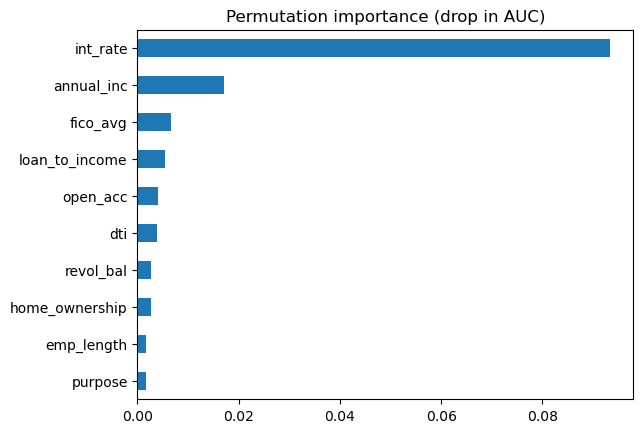

PD: 0.643 | top risk drivers: [('installment', 1.403), ('loan_to_income', 0.829), ('int_rate', 0.34)]
PD: 0.556 | top risk drivers: [('installment', 1.254), ('loan_to_income', 0.831), ('int_rate', 0.336)]
PD: 0.553 | top risk drivers: [('loan_to_income', 0.822), ('loan_amnt', 0.546), ('int_rate', 0.26)]


In [18]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

samp = test.sample(30000, random_state=0)
pi = permutation_importance(gbm, samp[num + cat], samp["is_default"],
                            scoring="roc_auc", n_repeats=3, random_state=0)
imp = pd.Series(pi.importances_mean, index=num + cat).sort_values(ascending=False)
print(imp.round(4))
imp.head(10).sort_values().plot(kind="barh", title="Permutation importance (drop in AUC)")
plt.show()

# Reason codes from the logistic model
pre_f = logit.named_steps["pre"]
names = pre_f.get_feature_names_out()
coef = logit.named_steps["m"].coef_[0]
dense = lambda x: x.toarray() if hasattr(x, "toarray") else x
base = dense(pre_f.transform(train[num + cat].sample(20000, random_state=0))).mean(axis=0)

def reasons(row_df, top=3):
    x = dense(pre_f.transform(row_df))[0]
    contrib = (x - base) * coef            # how much each feature pushes risk above an average borrower
    idx = np.argsort(-contrib)[:top]
    return [(names[i].split("__")[-1], round(float(contrib[i]), 3)) for i in idx]

risky = fin_set.sort_values("p_raw", ascending=False).head(3)
for i in range(3):
    row = risky.iloc[[i]]
    print("PD:", round(row["p_raw"].iloc[0], 3), "| top risk drivers:", reasons(row[num + cat]))

In [19]:
# Ranking quality and calibration by year (model fitted on 2010-2012)
rows = []
for y in [2013, 2014, 2015]:
    g = d[d["issue_year"] == y]
    p = m.predict_proba(g[num + cat])[:, 1]
    rows.append({"year": y, "loans": len(g),
                 "auc": round(roc_auc_score(g["is_default"], p), 4),
                 "avg_predicted": round(p.mean(), 4),
                 "actual": round(g["is_default"].mean(), 4)})
print(pd.DataFrame(rows))

def psi(ref, new, bins=10):
    ref, new = ref.dropna(), new.dropna()
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-4, None)
    n = np.clip(np.histogram(new, edges)[0] / len(new), 1e-4, None)
    return float(np.sum((n - r) * np.log(n / r)))

out = {c: psi(fit_set[c], fin_set[c]) for c in num}          # 2010-12 vs 2015
out["MODEL SCORE (2013-14 vs 2015)"] = psi(val_set["p_raw"], fin_set["p_raw"])
print(pd.Series(out).sort_values(ascending=False).round(3))

   year   loans     auc  avg_predicted  actual
0  2013  100422  0.6629         0.1361  0.1233
1  2014  162570  0.6622         0.1318  0.1373
2  2015  283019  0.6702         0.1212  0.1489
fico_avg                         0.174
dti                              0.166
int_rate                         0.141
credit_hist_years                0.133
open_acc                         0.082
loan_amnt                        0.069
MODEL SCORE (2013-14 vs 2015)    0.060
installment                      0.059
revol_util                       0.057
delinq_2yrs                      0.051
revol_bal                        0.038
total_acc                        0.031
annual_inc                       0.027
loan_to_income                   0.011
pub_rec                          0.000
dtype: float64


In [20]:
dense = lambda x: x.toarray() if hasattr(x, "toarray") else x

num_lr = [c for c in num if c != "installment"]
pre_lr = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_lr),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
])
logit2 = Pipeline([("pre", pre_lr), ("m", LogisticRegression(max_iter=1000))])
logit2.fit(fit_set[num_lr + cat], fit_set["is_default"])
fin_set["p_logit2"] = logit2.predict_proba(fin_set[num_lr + cat])[:, 1]

print("2015 AUC, logistic without installment:", round(roc_auc_score(fin_set["is_default"], fin_set["p_logit2"]), 4))
print("2015 AUC, gradient boosting:           ", round(roc_auc_score(fin_set["is_default"], fin_set["p_raw"]), 4))

pre2 = logit2.named_steps["pre"]
names2 = pre2.get_feature_names_out()
coef2 = logit2.named_steps["m"].coef_[0]

def orig(n):
    n = n.split("__", 1)[1]
    for c in cat:
        if n.startswith(c + "_"):
            return c
    return n

groups = np.array([orig(n) for n in names2])
base2 = dense(pre2.transform(fit_set[num_lr + cat].sample(20000, random_state=0))).mean(axis=0)

def reasons2(row_df, top=3):
    x = dense(pre2.transform(row_df))[0]
    contrib = pd.Series((x - base2) * coef2).groupby(groups).sum().sort_values(ascending=False)
    return [(k, round(float(v), 3)) for k, v in contrib.head(top).items()]

risky2 = fin_set.sort_values("p_logit2", ascending=False).head(3)
for i in range(3):
    row = risky2.iloc[[i]]
    print("PD:", round(row["p_logit2"].iloc[0], 3), "| defaulted:", int(row["is_default"].iloc[0]),
          "| drivers:", reasons2(row[num_lr + cat]))

2015 AUC, logistic without installment: 0.6667
2015 AUC, gradient boosting:            0.6702
PD: 1.0 | defaulted: 1 | drivers: [('pub_rec', 16.825), ('dti', 0.147), ('fico_avg', 0.146)]
PD: 0.999 | defaulted: 0 | drivers: [('pub_rec', 9.583), ('int_rate', 0.249), ('fico_avg', 0.186)]
PD: 0.965 | defaulted: 0 | drivers: [('pub_rec', 5.473), ('dti', 0.164), ('fico_avg', 0.105)]


In [21]:
num_ni = [c for c in num if c not in ("int_rate", "installment")]
cat_ni = [c for c in cat if c != "grade"]
pre_ni = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_ni),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_ni),
])
gbm_ni = Pipeline([("pre", pre_ni), ("m", HistGradientBoostingClassifier(
    max_depth=5, learning_rate=0.08, max_iter=300, random_state=42))])
gbm_ni.fit(fit_set[num_ni + cat_ni], fit_set["is_default"])
p_ni = gbm_ni.predict_proba(fin_set[num_ni + cat_ni])[:, 1]

y = fin_set["is_default"]
print("2015 AUC, grade only:                ", round(roc_auc_score(y, fin_set["p_grade"]), 4))
print("2015 AUC, with grade and rate (GBM): ", round(roc_auc_score(y, fin_set["p_raw"]), 4))
print("2015 AUC, WITHOUT grade, rate:       ", round(roc_auc_score(y, p_ni), 4))

2015 AUC, grade only:                 0.6675
2015 AUC, with grade and rate (GBM):  0.6702
2015 AUC, WITHOUT grade, rate:        0.6391


In [22]:
cols = ["fico_avg", "dti", "int_rate", "credit_hist_years", "annual_inc"]
pd.DataFrame({"2010-12": fit_set[cols].mean(),
              "2013-14": val_set[cols].mean(),
              "2015":    fin_set[cols].mean()}).round(2)

,2010-12,2013-14,2015
fico_avg,708.11,695.44,695.64
dti,15.33,17.28,18.47
int_rate,11.99,12.81,11.28
credit_hist_years,14.07,16.10,16.57
annual_inc,67088.67,71943.94,74523.60


In [23]:
from sklearn.preprocessing import FunctionTransformer

lo = fit_set[num_lr].quantile(0.01).values
hi = fit_set[num_lr].quantile(0.99).values
print("pub_rec in the 3 riskiest loans:", fin_set.loc[risky2.index, "pub_rec"].tolist())

pre3 = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("clip", FunctionTransformer(lambda X: np.clip(X, lo, hi))),
                      ("sc", StandardScaler())]), num_lr),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
])
logit3 = Pipeline([("pre", pre3), ("m", LogisticRegression(max_iter=1000))])
logit3.fit(fit_set[num_lr + cat], fit_set["is_default"])
fin_set["p_logit3"] = logit3.predict_proba(fin_set[num_lr + cat])[:, 1]
print("2015 AUC, capped logistic:", round(roc_auc_score(fin_set["is_default"], fin_set["p_logit3"]), 4))

#

pub_rec in the 3 riskiest loans: [86.0, 49.0, 28.0]
2015 AUC, capped logistic: 0.6671


In [24]:
# 1. Did the rate fall WITHIN each grade, or did the grade mix just improve?
print(d.pivot_table(index="grade", columns="issue_year", values="int_rate", aggfunc="mean").round(2))
print(d.groupby("issue_year")["grade"].value_counts(normalize=True).unstack().round(3))

# 2. Does the model without the rate predict 2015 defaults better?
rows = []
for y in [2013, 2014, 2015]:
    g = d[d["issue_year"] == y]
    rows.append({"year": y,
                 "actual": round(g["is_default"].mean(), 4),
                 "pred_with_rate": round(m.predict_proba(g[num + cat])[:, 1].mean(), 4),
                 "pred_without_rate": round(gbm_ni.predict_proba(g[num_ni + cat_ni])[:, 1].mean(), 4)})
pd.DataFrame(rows)

issue_year   2010   2011   2012   2013   2014   2015
grade                                               
A            7.15   7.08   7.60   7.70   7.45   6.90
B           10.71  11.01  12.13  11.80  11.19  10.02
C           13.52  13.93  15.24  15.39  14.07  13.24
D           15.18  16.19  18.25  18.66  17.03  16.64
E           16.85  18.19  20.84  21.57  20.32  19.11
F           18.76  19.94  22.92  23.92  24.18  23.54
G           20.54  21.44  24.62  25.75  25.73  26.87
grade           A      B      C      D      E      F      G
issue_year                                                 
2010        0.300  0.316  0.217  0.124  0.032  0.008  0.002
2011        0.396  0.335  0.156  0.089  0.019  0.004  0.001
2012        0.247  0.387  0.228  0.117  0.018  0.002  0.001
2013        0.170  0.401  0.246  0.144  0.032  0.006  0.000
2014        0.217  0.329  0.271  0.126  0.043  0.012  0.001
2015        0.248  0.324  0.274  0.116  0.033  0.005  0.001


,year,actual,pred_with_rate,pred_without_rate
0,2013,0.1233,0.1361,0.1352
1,2014,0.1373,0.1318,0.1439
2,2015,0.1489,0.1212,0.1440


In [26]:
fin_set["p_ni"] = p_ni
fin_set["exp_loss_ni"] = fin_set["p_ni"] * fin_set["lgd"] * fin_set["funded_amnt"]

act = fin_set["act_loss"].sum() / 1e6
for name, col in [("With rate", "exp_loss"), ("Without grade and rate", "exp_loss_ni")]:
    pred = fin_set[col].sum() / 1e6
    print(f"{name}: predicted {pred:.1f}M | actual {act:.1f}M | shortfall {100 * (1 - pred / act):.1f}%")

# Dollar-matched policy comparison including the no-rate model
fs = fin_set.sample(frac=1, random_state=0)
total_funded = fs["funded_amnt"].sum()
rows = []
for share in [0.6, 0.7, 0.8]:
    for name, col in [("Grade-only", "p_grade"), ("PD model (with rate)", "p_raw"),
                      ("PD model (no grade, no rate)", "p_ni")]:
        a = pick_by_dollars(col, True, share)
        rows.append({"share_of_dollars": share, "policy": name,
                     "default_rate_pct": round(100 * a["is_default"].mean(), 2),
                     "profit_millions": round(a["realized_profit"].sum() / 1e6, 1),
                     "roi_pct": round(100 * a["realized_profit"].sum() / a["funded_amnt"].sum(), 2)})
pd.DataFrame(rows)

With rate: predicted 165.7M | actual 201.5M | shortfall 17.8%
Without grade and rate: predicted 208.3M | actual 201.5M | shortfall -3.3%


,share_of_dollars,policy,default_rate_pct,profit_millions,roi_pct
0,0.6,Grade-only,9.14,156.0,7.18
1,0.6,PD model (with rate),8.97,157.9,7.26
2,0.6,"PD model (no grade, no rate)",10.49,157.3,7.23
3,0.7,Grade-only,10.77,180.2,7.10
4,0.7,PD model (with rate),10.16,182.4,7.19
5,0.7,"PD model (no grade, no rate)",11.50,181.2,7.14
6,0.8,Grade-only,11.99,202.8,7.00
7,0.8,PD model (with rate),11.45,204.9,7.07
8,0.8,"PD model (no grade, no rate)",12.55,203.4,7.01


In [27]:
for share in [0.6, 0.8]:
    diff = (flags("p_ni", True, share) - flags("p_grade", True, share)) * fs["realized_profit"].values
    tot = diff.sum() / 1e6
    se = diff.std(ddof=1) * np.sqrt(len(fs)) / 1e6
    print(f"{int(share*100)}% of dollars, no-rate model minus grade-only: {tot:.1f}M "
          f"(approx. range {tot - 1.96*se:.1f}M to {tot + 1.96*se:.1f}M)")

60% of dollars, no-rate model minus grade-only: 1.3M (approx. range -0.8M to 3.4M)
80% of dollars, no-rate model minus grade-only: 0.6M (approx. range -1.5M to 2.7M)


In [28]:
import os
os.makedirs("../outputs", exist_ok=True)

# 1. Holdout loans with scores (2015)
fin_set["risk_decile"] = fin_set["pd_decile"] + 1
keep = ["id", "issue_year", "grade", "purpose", "addr_state", "home_ownership", "annual_inc",
        "loan_amnt", "funded_amnt", "int_rate", "dti", "fico_avg", "is_default", "realized_profit",
        "p_grade", "p_raw", "p_ni", "exp_loss", "exp_loss_ni", "act_loss", "risk_decile"]
fin_set[keep].to_csv("../outputs/holdout_2015_scored.csv", index=False)

# 2. Grade x year trends (drift page)
g = d.groupby(["issue_year", "grade"]).agg(
    loans=("is_default", "count"), default_rate=("is_default", "mean"),
    avg_int_rate=("int_rate", "mean"), avg_fico=("fico_avg", "mean"), avg_dti=("dti", "mean"),
    profit=("realized_profit", "sum"), funded=("funded_amnt", "sum")).reset_index()
g["roi"] = g["profit"] / g["funded"]
g.to_csv("../outputs/grade_year_summary.csv", index=False)

# 3. Dollar-matched policy table
rows = []
for share in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    for name, col in [("Grade-only", "p_grade"), ("PD model (with rate)", "p_raw"),
                      ("PD model (no grade, no rate)", "p_ni")]:
        a = pick_by_dollars(col, True, share)
        rows.append({"share_of_dollars": share, "policy": name, "loans": len(a),
                     "default_rate": a["is_default"].mean(),
                     "funded_billions": a["funded_amnt"].sum() / 1e9,
                     "profit_millions": a["realized_profit"].sum() / 1e6,
                     "roi": a["realized_profit"].sum() / a["funded_amnt"].sum()})
pd.DataFrame(rows).to_csv("../outputs/policy_table.csv", index=False)

# 4. Predicted vs actual by year
rows = []
for y in [2013, 2014, 2015]:
    x = d[d["issue_year"] == y]
    pw = m.predict_proba(x[num + cat])[:, 1]
    pn = gbm_ni.predict_proba(x[num_ni + cat_ni])[:, 1]
    rows.append({"year": y, "loans": len(x), "actual": x["is_default"].mean(),
                 "pred_with_rate": pw.mean(), "pred_no_rate": pn.mean(),
                 "auc_with_rate": roc_auc_score(x["is_default"], pw),
                 "auc_no_rate": roc_auc_score(x["is_default"], pn)})
pd.DataFrame(rows).to_csv("../outputs/calibration_by_year.csv", index=False)

# 5. Loss reserve comparison
pd.DataFrame({"model": ["With rate", "Without grade and rate", "Actual"],
              "loss_millions": [fin_set["exp_loss"].sum() / 1e6,
                                fin_set["exp_loss_ni"].sum() / 1e6,
                                fin_set["act_loss"].sum() / 1e6]}).to_csv("../outputs/reserve.csv", index=False)

print(os.listdir("../outputs"))

['calibration_by_year.csv', 'grade_year_summary.csv', 'holdout_2015_scored.csv', 'policy_table.csv', 'reserve.csv', 'scored_test.csv']
